In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import f_classif, mutual_info_classif

from ucimlrepo import fetch_ucirepo # Importação de Dados
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# 1) Carga de Dados

In [3]:
# Busca do Dataset
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

# 2) Análise de Dados

### 2.1) Shape e Tipos

In [4]:
# União das Linhas e Colunas
df_iot2022 = pd.concat([x, y], axis=1)
target_column = y.columns[0]

print(f'Shape: {df_iot2022.shape}')
print(f'Target: {target_column}\n')

df_iot2022.head(5)

Shape: (123117, 84)
Target: Attack_type



,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,761.985779,29729182.96,32011597.87,4001449.734,10403073.63,4438.877106,1511693.954,2.026391e+06,506597.757339,680406.147100,761.985779,29729182.96,32011597.87,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2282414.913,2282414.913,2282414.913,2282414.913,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,247.001648,29855277.06,31883584.02,3985448.003,10463455.56,4214.048386,1576435.804,1.876261e+06,469065.249000,741351.686200,247.001648,29855277.06,31883584.02,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2028306.961,2028306.961,2028306.961,2028306.961,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,283.956528,29842149.02,32124053.00,4015506.625,10442377.92,2456.903458,1476048.946,2.013770e+06,503442.466300,660344.360027,283.956528,29842149.02,32124053.00,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2281903.982,2281903.982,2281903.982,2281903.982,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,74,8.222222,12.852799,0,21,30,6.0,8.689074,0,33,104,7.428571,11.229866,288.963318,29913774.97,31961063.15,3995132.893,10482528.22,3933.906555,1551892.042,1.883784e+06,470946.013927,724569.317900,288.963318,29913774.97,31961063.15,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2047288.179,2047288.179,2047288.179,2047288.179,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0,33,76,8.444444,13.115936,0,23,32,6.4,9.555103,0,33,108,7.714286,11.618477,387.907028,29814704.90,31902361.87,3987795.234,10447019.10,3005.027771,1632083.178,1.935984e+06,483996.033700,768543.390313,387.907028,2981

In [5]:
# Recuperação das colunas numéricas
numeric_columns = df_iot2022.select_dtypes(include=np.number).columns.to_list()
print(f'Quantidade de Colunas Numéricas: {len(numeric_columns)}')

Quantidade de Colunas Numéricas: 81


### 2.2) Avaliação de Duplicadas e Valores Nulos

In [20]:
# Verificação de Linhas Duplicadas
print(f'Linhas Duplicadas: {df_iot2022.duplicated().sum()}')
print(f'% Duplicadas: {df_iot2022.duplicated().mean() * 100:.2f}\n')

null_values = df_iot2022.isnull().sum()
percent = round(null_values/len(df_iot2022) * 100, 2)

df_null_values = pd.DataFrame({"nulos": null_values, "(%)": percent}).sort_values(by='nulos', ascending=False)

print(f'Valores Nulos: {df_null_values[df_null_values['nulos'] > 0]}' if (null_values > 0).any() else 'Sem Valores Nulos')

Linhas Duplicadas: 5195
% Duplicadas: 4.22

Sem Valores Nulos


### 2.3) Distribuição do Target

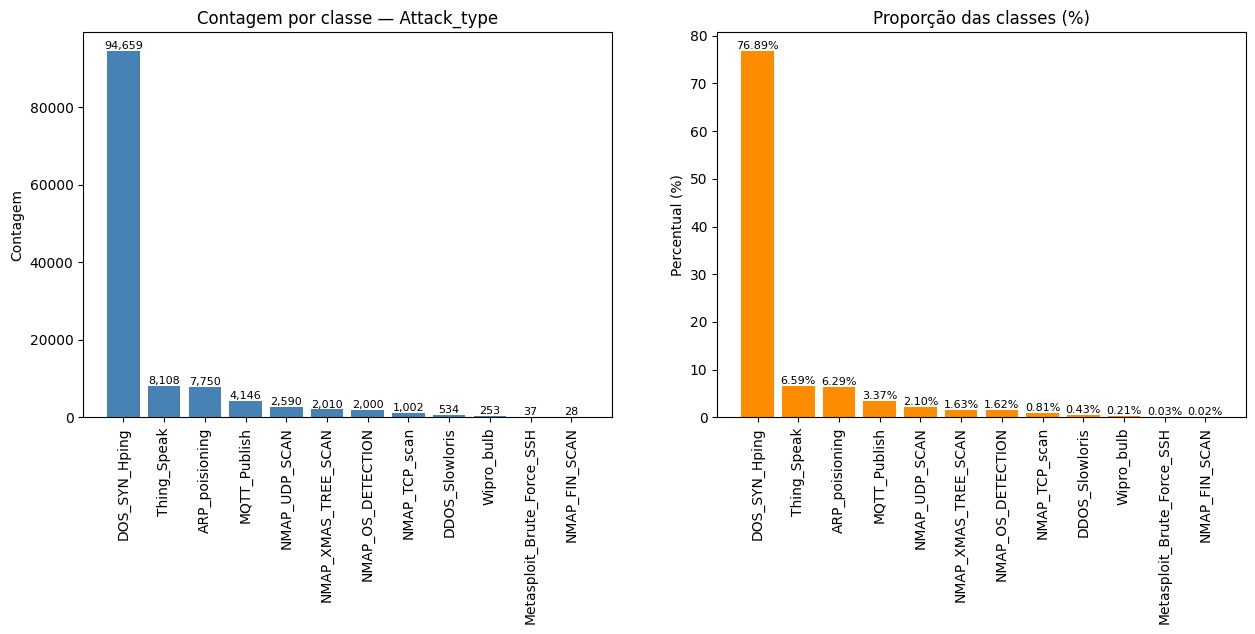

In [19]:
df_volumetry = df_iot2022[target_column].value_counts()
df_percent = round(df_iot2022[target_column].value_counts(normalize=True) * 100, 2)

# Volumetria por Classe
fig, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].bar(df_volumetry.index.astype(str), df_volumetry.values, color='steelblue')
axes[0].set_title(f'Contagem por classe — {target_column}')
axes[0].set_ylabel('Contagem')
for i, v in enumerate(df_volumetry.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
axes[0].tick_params(axis='x', rotation=90)


axes[1].bar(df_percent.index.astype(str), df_percent.values, color='darkorange')
axes[1].set_title('Proporção das classes (%)')
axes[1].set_ylabel('Percentual (%)')
for i, v in enumerate(df_percent.values):
    axes[1].text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontsize=8)
axes[1].tick_params(axis='x', rotation=90)
plt.show()

### 2.4) Identificação de Outliers

In [8]:
def outlier_detection(pd_series: pd.Series):
    """ 
    Detecção de Outliers através da diferença entre o terceiro e o primeiro qquartil 
    """
    Q1 = pd_series.quantile(0.25)
    Q3 = pd_series.quantile(0.75)
    IQR = Q3 - Q1 

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR) 

    return  int(((pd_series < lower_limit) | (pd_series > upper_limit)).sum())

In [9]:
outlier_iqr = df_iot2022[numeric_columns].apply(outlier_detection).sort_values(ascending=False)
percent_iqr = round(outlier_iqr/len(df_iot2022) * 100, 2)

df_outliers = pd.DataFrame(data={"qtd_outliers": outlier_iqr, "pct_outliers": percent_iqr})
print(df_outliers[df_outliers['qtd_outliers'] > 0])

                       qtd_outliers  pct_outliers
flow_pkts_payload.avg         38116         30.96
bwd_header_size_tot           33148         26.92
bwd_header_size_max           33137         26.92
flow_ACK_flag_count           33083         26.87
bwd_pkts_tot                  32364         26.29
bwd_subflow_pkts              32343         26.27
bwd_header_size_min           32065         26.04
fwd_pkts_payload.min          28458         23.11
fwd_pkts_payload.max          28458         23.11
fwd_pkts_payload.avg          28458         23.11
fwd_init_window_size          28458         23.11
fwd_last_window_size          28458         23.11
fwd_subflow_bytes             28455         23.11
flow_pkts_payload.tot         28455         23.11
fwd_pkts_payload.tot          28454         23.11
id.resp_p                     28452         23.11
flow_pkts_payload.max         28216         22.92
flow_RST_flag_count           27898         22.66
flow_SYN_flag_count           27362         22.22


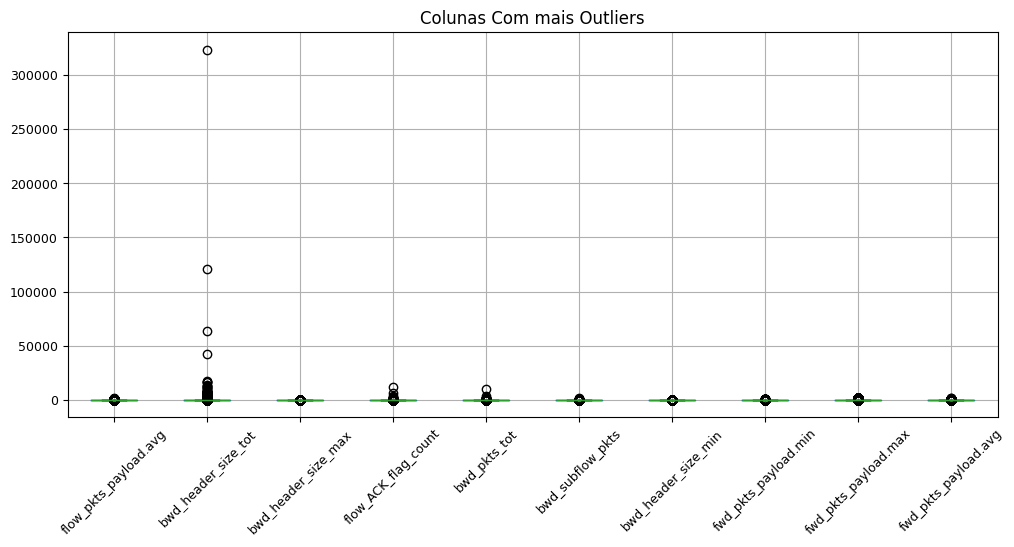

In [10]:
top_10_outliers = df_outliers.head(10).index

df_iot2022[top_10_outliers].boxplot(figsize=(12, 5), rot=45, fontsize=9)
plt.title("Colunas Com mais Outliers")
plt.show()

# 3) Relevância das Features

### 3.1) Avaliação das Relações Lineares

In [11]:
df_correlation = pd.get_dummies(data=df_iot2022, columns=['proto', 'service'], drop_first=True)

df_numeric_correlation = df_correlation.select_dtypes(include=np.number).columns.to_list()
X_numeric = df_correlation[df_numeric_correlation]

encoding = LabelEncoder()
y_encoded = encoding.fit_transform(df_iot2022['Attack_type'])

In [12]:
# Detecta as relações lineares entre as colunas numéricas e a variável target
f_scores, p_class = f_classif(X=X_numeric, y=y_encoded)

# Detecta as relações lineares e não lineares entre as colunas numéricas e a variável target
mi_scores = mutual_info_classif(X_numeric, y_encoded, discrete_features=False, random_state=42)

print(f'F-Score: {f_scores}\n')
print(f'P-Value: {p_class}\n')
print(f'Mi-Score: {mi_scores}\n')

c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [24] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\rpf97\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


F-Score: [1.88765818e+03 8.28644352e+03 5.36760587e+02 4.43429197e+02
 6.31136801e+01 2.95300040e+02 4.29482947e+01 3.25594372e+03
 3.25929867e+03 3.25764783e+03 2.71498646e+03 5.61561476e+02
 1.13965750e+04 8.02617888e+03 5.08266073e+01 4.27322729e+03
 4.94209044e+03 6.76429252e+03 9.29836607e+03 6.10958426e+03
 5.97374774e+02 3.45390541e+02 1.30021695e+02 5.52084007e+06
            nan 1.34815651e+02 2.06010925e+02 1.64214472e+05
 1.98952923e+03 1.58230934e+02 2.35767774e+04 2.71066930e+03
 4.03003454e+03 5.35137406e+03 1.11155917e+01 5.27257169e+03
 5.03172182e+03 4.85729862e+02 3.47073479e+03 1.72660563e+01
 3.00392484e+03 2.00741394e+03 5.03086000e+00 2.00540585e+04
 5.36780086e+02 3.42399789e+03 1.69086588e+04 5.88347395e+01
 9.81957436e+02 2.71722635e+02 7.48598649e+02 7.62979148e+02
 3.36802503e+01 1.97583535e+04 5.36950479e+02 7.16442870e+03
 1.64114189e+04 3.75033717e+03 2.99869548e+03 3.65731794e+02
 4.63968378e+02 5.61912693e+01 1.47212954e+01 4.90813022e+00
 3.07097124e+01

### 3.2) Investigação do Top Feature

In [13]:
df_scores = pd.DataFrame({
    "feature": X_numeric.columns,
    "f_score": f_scores,
    "p_value": p_class,
    "mi": mi_scores
}).sort_values('f_score', ascending=False)

df_scores

,feature,f_score,p_value,mi
23,fwd_URG_flag_count,5.520840e+06,0.000000e+00,0.082397
27,fwd_pkts_payload.min,1.642145e+05,0.000000e+00,0.687369
80,fwd_last_window_size,5.640489e+04,0.000000e+00,0.768491
73,idle.min,2.377376e+04,0.000000e+00,0.173199
30,fwd_pkts_payload.avg,2.357678e+04,0.000000e+00,0.863119
76,idle.avg,2.168906e+04,0.000000e+00,0.173470
78,fwd_init_window_size,2.086841e+04,0.000000e+00,0.700307
43,fwd_iat.max,2.005406e+04,0.000000e+00,0.496456
53,flow_iat.max,1.975835e+04,0.000000e+00,0.670723
74,idle.max,1.937172e+04,0.000000e+00,0.174021


In [14]:
# Avaliar as distribuição Top 1 por classe
top_feature = df_scores.iloc[0]['feature']

df_iot2022.groupby("Attack_type")[top_feature].agg(['mean','std','min','max','count'])

,mean,std,min,max,count
Attack_type,,,,,
ARP_poisioning,0.00000,0.000000,0,0,7750
DDOS_Slowloris,0.00000,0.000000,0,0,534
DOS_SYN_Hping,0.00000,0.000000,0,0,94659
MQTT_Publish,0.00000,0.000000,0,0,4146
Metasploit_Brute_Force_SSH,0.00000,0.000000,0,0,37
NMAP_FIN_SCAN,0.00000,0.000000,0,0,28
NMAP_OS_DETECTION,0.00000,0.000000,0,0,2000
NMAP_TCP_scan,0.00000,0.000000,0,0,1002
NMAP_UDP_SCAN,0.00000,0.000000,0,0,2590


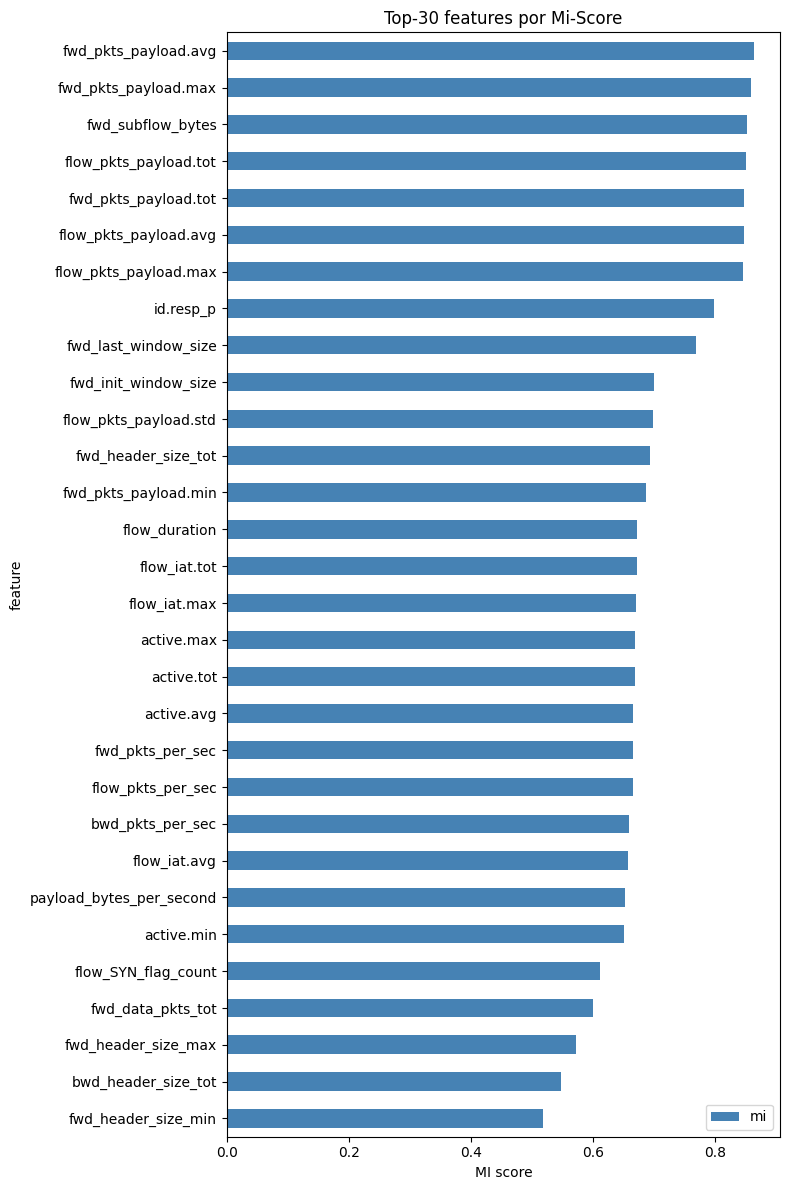

In [15]:
fig, ax = plt.subplots(figsize=(8, 12))

df_scores.sort_values(by='mi', ascending=False).head(30).iloc[::-1].plot.barh(
    x='feature', y='mi', ax=ax, color='steelblue'
)
ax.set_title('Top-30 features por Mi-Score')
ax.set_xlabel('MI score')
plt.tight_layout()
plt.show()


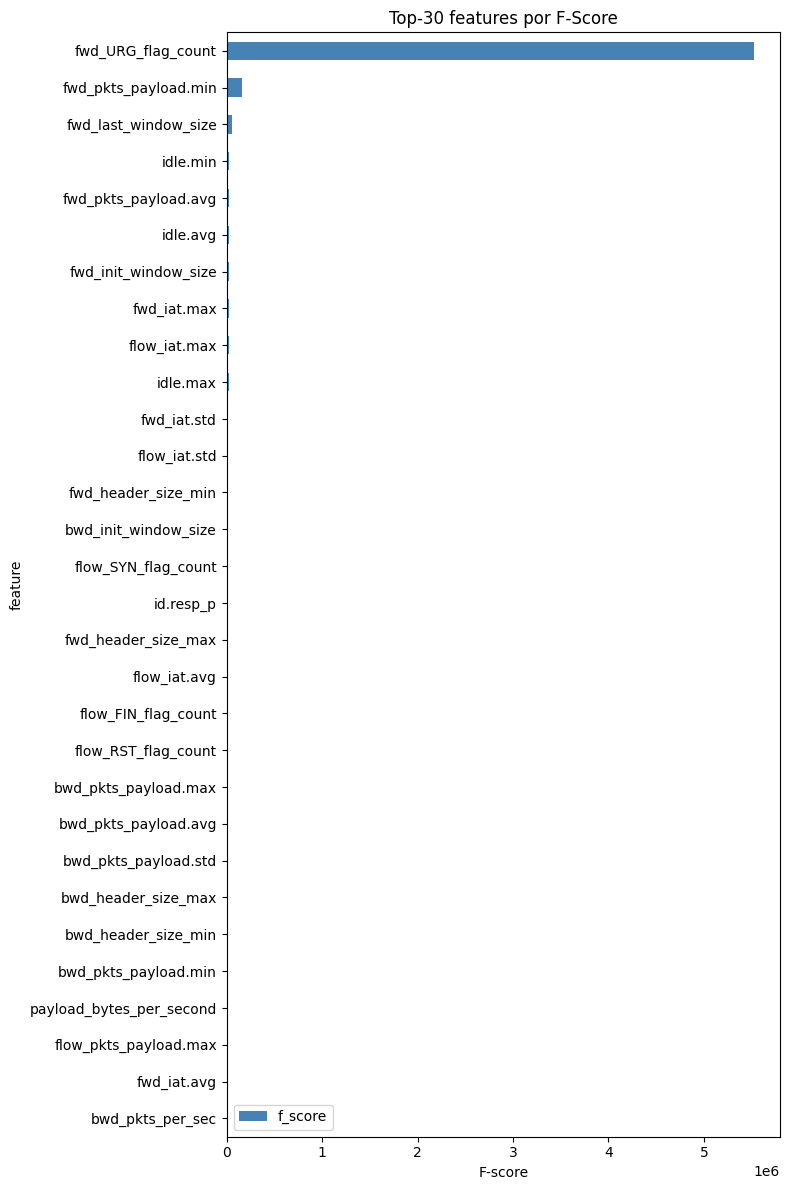

In [16]:
fig, ax = plt.subplots(figsize=(8, 12))

df_scores.sort_values(by='f_score', ascending=False).head(30).iloc[::-1].plot.barh(
    x='feature', y='f_score', ax=ax, color='steelblue'
)
ax.set_title('Top-30 features por F-Score')
ax.set_xlabel('F-score')
plt.tight_layout()
plt.show()


### 3.3) Avaliação com as colunas Numéricas

In [17]:
corrleation_list = X_numeric.corr(method="spearman").abs()
upper = corrleation_list.where(np.triu(np.ones(corrleation_list.shape), k=1).astype(bool))
redundants = [c for c in upper.columns if (upper[c] > 0.95).any()]

print(f'Total de Colunas Redundantes: {len(redundants)}')

Total de Colunas Redundantes: 45


Avaliação de Duplicadas

In [18]:
df_clean = df_iot2022.drop_duplicates().reset_index(drop=True)

print(f'Antes: {len(df_iot2022)} | Depois: {len(df_clean)} | Removidas: {len(df_iot2022) - len(df_clean)}')

Antes: 123117 | Depois: 117922 | Removidas: 5195


Avaliação da Força das variáveis categóricas

In [ ]:
def cramers_v(var1, var2):
    # Criação da tabela de contingência
    main_table = pd.cross_tab(var1, var2)

    chi2, _ = chi2_contingency(main_table)

    # V de Cramer
    return float(
        np.sqrt(chi2 / (main_table.sum().sum() * (min(main_table.shape) - 1)))
    )